# Qwen3.5-27B BF16 LoRA Weight-Shortcut Study (96GB)

Fine-tune Qwen3.5-27B with outcome-only supervision and measure changes in the total-weight shortcut.

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/157b571be6ffaa91.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 16 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 16 tracked cells.


## 1. Protocol, dataset construction, and leakage barriers

The split is fixed before loading the model.


In [2]:
%%cell_progress 1/16 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        candidate for candidate in PROJECT_CANDIDATES
        if (candidate / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/16 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/16 Install and verify the BF16 LoRA environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring allocator and Hugging Face cache before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing unused TorchAudio and incompatible TorchAO')
subprocess.run(
    [
        sys.executable, '-m', 'pip', 'uninstall', '-y',
        'torchaudio', 'torchao',
    ],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned model and PEFT dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0',
    'peft==0.20.0',
    'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import LoraConfig, get_peft_model
from torch.utils.data import Dataset
from transformers import Trainer, TrainingArguments
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
try:
    remaining_torchao = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    remaining_torchao = None
assert remaining_torchao is None, (
    'TorchAO is not used by this BF16 experiment and must be removed to avoid '
    'PEFT treating an incompatible Colab preinstall as an active backend.',
    remaining_torchao,
)
print('torchao:', remaining_torchao)
print('Toolkit source:', toolkit_path)


Install and verify the BF16 LoRA environment:   6%|6         | 1/16 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
torchao: None
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/16 Verify the 96GB Blackwell runtime and access
cell_stage('Checking CUDA capacity and Blackwell support')
assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
GPU_CAPABILITY = torch.cuda.get_device_capability(0)
print('GPU:', GPU_NAME)
print('CUDA memory (GiB):', round(GPU_MEMORY_GIB, 1))
print('Compute capability:', GPU_CAPABILITY)
assert GPU_MEMORY_GIB >= 88, (
    'This BF16 protocol requires a GPU exposing at least 88 GiB.',
    GPU_NAME, GPU_MEMORY_GIB,
)
if GPU_CAPABILITY[0] >= 10:
    cuda_tuple = tuple(int(value) for value in torch.version.cuda.split('.')[:2])
    assert cuda_tuple >= (12, 8), (
        'Blackwell requires a PyTorch build with CUDA 12.8 or newer.',
        torch.__version__, torch.version.cuda,
    )

cell_stage('Checking local checkpoint space')
import shutil
LOCAL_DISK_FREE_GIB = shutil.disk_usage('/content').free / 2**30
print('Local disk free (GiB):', round(LOCAL_DISK_FREE_GIB, 1))
if LOCAL_DISK_FREE_GIB < 90:
    print(
        'Warning: free at least 90 GiB when possible. The BF16 checkpoint, '
        'cache, and temporary files are large.'
    )

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        login(token=hf_token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. The public checkpoint may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify the 96GB Blackwell runtime and access:  12%|#2        | 2/16 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GiB): 95.0
Compute capability: (12, 0)
Local disk free (GiB): 188.2
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/16 Set the single editable experiment configuration
cell_stage('Freezing the intended training regime and resource envelope')

# Change OUTPUT_VERSION whenever any scientific or training choice changes.
OUTPUT_VERSION = 'v1'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64

SEED = 20260903
TARGET_TRAIN_SCENE_OCCURRENCES = 360  # 40 per 3x3 cell; divisible by 9.
MIN_UNIQUE_TRAIN_SCENES_PER_CELL = 10
MAX_REPEAT_PER_TRAIN_SCENE = 4
TRAIN_PERMUTATIONS_PER_SCENE = 3      # Exactly one correct A, B, and C.
MAX_DEV_SCENES = None                 # None = use all untouched probe_dev scenes.
EVAL_BATCH_SIZE = 2

LORA_RANK = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
LEARNING_RATE = 1.0e-4
WEIGHT_DECAY = 0.0
NUM_TRAIN_EPOCHS = 1.0
TRAIN_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 16
LOGGING_STEPS = 5
EVAL_STEPS = 25
SAVE_STEPS = 25
WARMUP_RATIO = 0.03

RUN_BASELINE_EVALUATION = True
BOOTSTRAP_REPLICATES = 10000

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_bf16_lora_weight_shortcut_{OUTPUT_VERSION}'
)
MANIFEST_DIR = OUTPUT_ROOT / 'manifests'
CHECKPOINT_DIR = OUTPUT_ROOT / 'checkpoints'
ADAPTER_DIR = OUTPUT_ROOT / 'adapter_final'
BASELINE_SHARD_DIR = OUTPUT_ROOT / 'baseline_eval_shards'
ADAPTED_SHARD_DIR = OUTPUT_ROOT / 'adapted_eval_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (
    OUTPUT_ROOT, MANIFEST_DIR, CHECKPOINT_DIR, BASELINE_SHARD_DIR,
    ADAPTED_SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

assert TARGET_TRAIN_SCENE_OCCURRENCES % 9 == 0
assert TRAIN_PERMUTATIONS_PER_SCENE == 3
print('Output:', OUTPUT_ROOT)
print('Target train examples:', (
    TARGET_TRAIN_SCENE_OCCURRENCES * TRAIN_PERMUTATIONS_PER_SCENE
))


Set the single editable experiment configuration:  19%|#8        | 3/16 [00:00<?, ?cell/s]

Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1
Target train examples: 1080


In [6]:
%%cell_progress 5/16 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile
import shutil

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [member for member in bundle.infolist() if not member.is_dir()]
            extraction_root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
        if not dataset_complete(DATASET_DIR):
            nested_roots = [
                candidate for candidate in DATASET_DIR.iterdir()
                if dataset_complete(candidate)
            ]
            assert len(nested_roots) == 1, (
                'Archive must contain Dataset v1 either at its root or inside '
                'one top-level directory.', nested_roots,
            )
            DATASET_DIR = nested_roots[0]
    elif dataset_complete(LEGACY_DATASET_DIR):
        cell_stage('Copying Dataset v1 from Drive to the local SSD')
        shutil.copytree(LEGACY_DATASET_DIR, DATASET_DIR, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            'Dataset v1 was not found. Run the existing dataset build/cache '
            'notebook and place dataset_v1.zip under VisualTorque/data/.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  25%|##5       | 4/16 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/16 Load scenes and expose shortcut structure
cell_stage('Loading exact scene records and frozen probe splits')
import hashlib
from collections import Counter, defaultdict

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(file_path)

def sha256_file(file_path):
    digest = hashlib.sha256()
    with Path(file_path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def stable_key(value, seed=SEED):
    return hashlib.sha256(f'{seed}:{value!r}'.encode('utf-8')).hexdigest()

def side_from_comparison(left_value, right_value):
    if left_value > right_value:
        return 'left'
    if left_value < right_value:
        return 'right'
    return 'balanced'

def weight_cue(scene):
    derived = scene['derived']
    return side_from_comparison(
        int(derived['left_units']), int(derived['right_units'])
    )

def farthest_distance_cue(scene):
    left = max(
        (int(stack['distance']) for stack in scene['stacks'] if stack['side'] == 'left'),
        default=0,
    )
    right = max(
        (int(stack['distance']) for stack in scene['stacks'] if stack['side'] == 'right'),
        default=0,
    )
    return side_from_comparison(left, right)

def shortcut_relation(scene):
    cue = weight_cue(scene)
    outcome = scene['derived']['outcome']
    if cue == 'balanced':
        return 'weight_neutral'
    if cue == outcome:
        return 'weight_aligned'
    return 'weight_conflict'

scenes = read_jsonl(DATASET_DIR / 'scenes.jsonl')
questions = read_jsonl(DATASET_DIR / 'questions.jsonl')
split_record = json.loads(
    (DATASET_DIR / 'splits.json').read_text(encoding='utf-8')
)
scene_by_id = {row['scene_id']: row for row in scenes}
assert len(scene_by_id) == len(scenes)

scene_rows = []
for scene in scenes:
    scene_rows.append({
        'scene_id': scene['scene_id'],
        'split': scene['split'],
        'structure': scene.get('metadata', {}).get(
            'family',
            'multi_stack' if scene['problem_type'] == 'multi_stack' else 'single_stack',
        ),
        'problem_type': scene['problem_type'],
        'outcome': scene['derived']['outcome'],
        'weight_cue': weight_cue(scene),
        'distance_cue': farthest_distance_cue(scene),
        'shortcut_relation': shortcut_relation(scene),
        'net_torque': int(scene['derived']['net_torque']),
    })
scene_frame = pd.DataFrame(scene_rows)

for split_name in ('probe_train', 'probe_dev', 'probe_test'):
    current = scene_frame[scene_frame['split'] == split_name]
    print('\n', split_name, '| scenes:', len(current))
    display(pd.crosstab(current['weight_cue'], current['outcome']))

heldout_combinations = {
    tuple(item) for item in split_record['heldout_unit_distance_combinations']
}
print('Held-out unit-distance combinations:', sorted(heldout_combinations))


Load scenes and expose shortcut structure:  31%|###1      | 5/16 [00:00<?, ?cell/s]


 probe_train | scenes: 985


outcome,balanced,left,right
weight_cue,,,
balanced,25,76,77
left,14,313,75
right,11,76,318



 probe_dev | scenes: 108


outcome,balanced,left,right
weight_cue,,,
balanced,2,6,7
left,1,32,13
right,1,9,37



 probe_test | scenes: 1007


outcome,balanced,left,right
weight_cue,,,
balanced,16,81,79
left,11,335,71
right,14,75,325


Held-out unit-distance combinations: [(2, 1), (2, 6), (4, 3), (4, 5), (5, 3), (5, 5)]


In [8]:
%%cell_progress 7/16 Build balanced train, dev, and frozen test manifests
cell_stage('Loading image-rule outcome examples for each frozen split')

def load_split_examples(split_name):
    config = BehaviorRunConfig(
        dataset_dir=DATASET_DIR,
        output_dir=OUTPUT_ROOT / '_unused_behavior_config',
        model_id=MODEL_ID,
        model_revision=MODEL_REVISION,
        conditions=(PromptCondition.IMAGE_RULE,),
        question_kinds=('outcome',),
        splits=(split_name,),
        batch_size=EVAL_BATCH_SIZE,
        seed=SEED,
    )
    return list(load_behavior_examples(config))

examples_by_split = {
    split_name: load_split_examples(split_name)
    for split_name in ('probe_train', 'probe_dev', 'probe_test')
}
examples_by_split_scene = {}
for split_name, examples in examples_by_split.items():
    grouped = defaultdict(list)
    for example in examples:
        grouped[example.scene_id].append(example)
    examples_by_split_scene[split_name] = dict(grouped)
    assert all(len(rows) == 6 for rows in grouped.values()), (
        split_name, Counter(len(rows) for rows in grouped.values())
    )

SIDES = ('left', 'balanced', 'right')
BALANCE_CELLS = tuple((cue, outcome) for cue in SIDES for outcome in SIDES)

def balance_with_replacement(frame, total_occurrences):
    assert total_occurrences % len(BALANCE_CELLS) == 0
    target_per_cell = total_occurrences // len(BALANCE_CELLS)
    occurrences = []
    support = {}
    for cue, outcome in BALANCE_CELLS:
        current = frame[
            (frame['weight_cue'] == cue) & (frame['outcome'] == outcome)
        ].copy()
        current = current.sort_values(
            'scene_id', key=lambda column: column.map(stable_key)
        )
        support[f'{cue}|{outcome}'] = int(len(current))
        assert len(current) >= MIN_UNIQUE_TRAIN_SCENES_PER_CELL, (
            'Insufficient unique probe_train support for a defensible balanced '
            'SFT cell. Regenerate/expand Dataset v1 rather than heavily '
            'duplicating a rare cell.', cue, outcome, len(current)
        )
        repeat_factor = (target_per_cell + len(current) - 1) // len(current)
        assert repeat_factor <= MAX_REPEAT_PER_TRAIN_SCENE, (
            'A training cell would repeat an individual scene too often. '
            'Expand Dataset v1 or lower TARGET_TRAIN_SCENE_OCCURRENCES.',
            cue, outcome, len(current), repeat_factor,
        )
        rows = current.to_dict(orient='records')
        for index in range(target_per_cell):
            source = rows[index % len(rows)]
            occurrences.append({
                **source,
                'occurrence_id': f"{source['scene_id']}__occ{index // len(rows):03d}",
                'cell_repeat_index': index // len(rows),
            })
    occurrences.sort(key=lambda row: stable_key(row['occurrence_id']))
    return occurrences, support

def balanced_without_replacement(frame, max_scenes=None):
    grouped = {}
    for cue, outcome in BALANCE_CELLS:
        current = frame[
            (frame['weight_cue'] == cue) & (frame['outcome'] == outcome)
        ].copy()
        current = current.sort_values(
            'scene_id', key=lambda column: column.map(stable_key)
        )
        assert len(current) > 0, (
            'A balanced evaluation cell is empty.', cue, outcome
        )
        grouped[(cue, outcome)] = current.to_dict(orient='records')
    target = min(len(rows) for rows in grouped.values())
    if max_scenes is not None:
        target = min(target, max_scenes // len(BALANCE_CELLS))
    assert target >= 1
    selected = [
        row
        for cell in BALANCE_CELLS
        for row in grouped[cell][:target]
    ]
    selected.sort(key=lambda row: stable_key(row['scene_id']))
    return selected

train_pool = scene_frame[scene_frame['split'] == 'probe_train'].copy()
dev_pool = scene_frame[scene_frame['split'] == 'probe_dev'].copy()
test_pool = scene_frame[scene_frame['split'] == 'probe_test'].copy()

train_occurrences, train_unique_support = balance_with_replacement(
    train_pool, TARGET_TRAIN_SCENE_OCCURRENCES
)
# Dev is only for checkpoint selection, so keep it representative of the
# untouched probe_dev distribution instead of requiring every diagnostic cell.
# (Small dataset builds may legitimately omit one of the 3x3 cells in dev.)
dev_scenes = dev_pool.sort_values(
    'scene_id', key=lambda column: column.map(stable_key)
).to_dict(orient='records')
if MAX_DEV_SCENES is not None:
    dev_scenes = dev_scenes[:MAX_DEV_SCENES]
assert dev_scenes, 'probe_dev is empty.'

test_balanced_scenes = balanced_without_replacement(test_pool)
test_balanced_ids = {row['scene_id'] for row in test_balanced_scenes}

def choose_label_balanced_examples(split_name, scene_id, occurrence_id):
    by_label = defaultdict(list)
    for example in examples_by_split_scene[split_name][scene_id]:
        by_label[example.gold_label].append(example)
    assert set(by_label) == {'A', 'B', 'C'}
    selected = []
    for label in ('A', 'B', 'C'):
        candidates = sorted(by_label[label], key=lambda row: row.question_id)
        offset = int(stable_key(f'{occurrence_id}:{label}')[:8], 16) % len(candidates)
        selected.append(candidates[offset])
    return selected

train_examples = []
train_manifest = []
for occurrence in train_occurrences:
    selected = choose_label_balanced_examples(
        'probe_train', occurrence['scene_id'], occurrence['occurrence_id']
    )
    for example in selected:
        train_examples.append(example)
        train_manifest.append({
            'training_instance_id': (
                f"{occurrence['occurrence_id']}__{example.question_id}"
            ),
            'scene_id': example.scene_id,
            'source_question_id': example.question_id,
            'source_split': example.split,
            'gold_label': example.gold_label,
            'outcome': occurrence['outcome'],
            'weight_cue': occurrence['weight_cue'],
            'shortcut_relation': occurrence['shortcut_relation'],
            'problem_type': occurrence['problem_type'],
            'cell_repeat_index': occurrence['cell_repeat_index'],
        })

dev_examples = []
dev_manifest = []
for scene in dev_scenes:
    selected = choose_label_balanced_examples(
        'probe_dev', scene['scene_id'], scene['scene_id']
    )
    for example in selected:
        dev_examples.append(example)
        dev_manifest.append({
            'scene_id': example.scene_id,
            'source_question_id': example.question_id,
            'source_split': example.split,
            'gold_label': example.gold_label,
            'outcome': scene['outcome'],
            'weight_cue': scene['weight_cue'],
            'shortcut_relation': scene['shortcut_relation'],
        })

# All six mappings are retained for final semantic aggregation.
test_examples = examples_by_split['probe_test']
test_manifest = []
for example in test_examples:
    scene = scene_by_id[example.scene_id]
    test_manifest.append({
        'scene_id': example.scene_id,
        'source_question_id': example.question_id,
        'source_split': example.split,
        'gold_label': example.gold_label,
        'outcome': scene['derived']['outcome'],
        'weight_cue': weight_cue(scene),
        'shortcut_relation': shortcut_relation(scene),
        'problem_type': scene['problem_type'],
        'balanced_shortcut_test': example.scene_id in test_balanced_ids,
    })

write_jsonl_atomic(MANIFEST_DIR / 'train_manifest.jsonl', train_manifest)
write_jsonl_atomic(MANIFEST_DIR / 'dev_manifest.jsonl', dev_manifest)
write_jsonl_atomic(MANIFEST_DIR / 'test_manifest.jsonl', test_manifest)
write_json_atomic(MANIFEST_DIR / 'train_unique_support.json', train_unique_support)
write_json_atomic(MANIFEST_DIR / 'balanced_test_scene_ids.json', {
    'scene_ids': sorted(test_balanced_ids),
    'count': len(test_balanced_ids),
})
print('Train examples:', len(train_examples))
print('Dev examples:', len(dev_examples))
print('Frozen test examples:', len(test_examples))
print('Balanced test scenes:', len(test_balanced_ids))


Build balanced train, dev, and frozen test manifests:  38%|###7      | 6/16 [00:00<?, ?cell/s]

Train examples: 1080
Dev examples: 324
Frozen test examples: 6042
Balanced test scenes: 99


In [9]:
%%cell_progress 8/16 Audit leakage, shortcut balance, and lock the protocol
cell_stage('Checking split isolation and realized training independence')

train_unique_ids = {row['scene_id'] for row in train_occurrences}
dev_ids = {row['scene_id'] for row in dev_scenes}
test_ids = set(test_pool['scene_id'])
assert not (train_unique_ids & dev_ids)
assert not (train_unique_ids & test_ids)
assert not (dev_ids & test_ids)
assert all(row['source_split'] == 'probe_train' for row in train_manifest)
assert all(row['source_split'] == 'probe_dev' for row in dev_manifest)
assert all(row['source_split'] == 'probe_test' for row in test_manifest)

train_occurrence_frame = pd.DataFrame(train_occurrences)
train_contingency = pd.crosstab(
    train_occurrence_frame['weight_cue'],
    train_occurrence_frame['outcome'],
).reindex(index=SIDES, columns=SIDES, fill_value=0)
assert train_contingency.to_numpy().min() == train_contingency.to_numpy().max()

train_weight_only_accuracy = float(
    (train_occurrence_frame['weight_cue'] == train_occurrence_frame['outcome']).mean()
)
assert abs(train_weight_only_accuracy - 1 / 3) < 1e-12
scene_repeat_counts = train_occurrence_frame['scene_id'].value_counts()
realized_max_repeat = int(scene_repeat_counts.max())
assert realized_max_repeat <= MAX_REPEAT_PER_TRAIN_SCENE

train_example_frame = pd.DataFrame(train_manifest)
label_counts = train_example_frame['gold_label'].value_counts().to_dict()
assert len(set(label_counts.values())) == 1, label_counts

for row in scenes:
    if row['split'] != 'probe_test':
        assert not any(
            (int(stack['units']), int(stack['distance'])) in heldout_combinations
            for stack in row['stacks']
        )

balanced_test_frame = scene_frame[scene_frame['scene_id'].isin(test_balanced_ids)]
balanced_test_contingency = pd.crosstab(
    balanced_test_frame['weight_cue'], balanced_test_frame['outcome']
).reindex(index=SIDES, columns=SIDES, fill_value=0)
assert balanced_test_contingency.to_numpy().min() == balanced_test_contingency.to_numpy().max()
assert balanced_test_frame['scene_id'].nunique() == len(test_balanced_ids)

dataset_fingerprint = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=OUTPUT_ROOT,
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
).dataset_fingerprint()

protocol_identity = {
    'schema_version': 'qwen27b-bf16-lora-weight-shortcut-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'model_dtype': MODEL_DTYPE,
    'dataset_fingerprint': dataset_fingerprint,
    'training_regime': 'outcome_only_image_rule_no_cot',
    'train_source_split': 'probe_train',
    'checkpoint_selection_split': 'probe_dev',
    'final_test_split': 'probe_test',
    'train_balance': 'exact 3x3 total-weight-cue by physical-outcome balance',
    'train_scene_occurrences': len(train_occurrences),
    'train_unique_scenes': len(train_unique_ids),
    'train_examples': len(train_examples),
    'train_option_permutations_per_scene_occurrence': 3,
    'max_repeat_per_train_scene': MAX_REPEAT_PER_TRAIN_SCENE,
    'realized_max_repeat_per_train_scene': realized_max_repeat,
    'train_weight_only_accuracy': train_weight_only_accuracy,
    'dev_scenes': len(dev_ids),
    'test_scenes': len(test_ids),
    'balanced_shortcut_test_scenes': len(test_balanced_ids),
    'lora': {
        'rank': LORA_RANK,
        'alpha': LORA_ALPHA,
        'dropout': LORA_DROPOUT,
        'scope': 'decoder linear modules only; vision and projector frozen',
    },
    'optimization': {
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'epochs': NUM_TRAIN_EPOCHS,
        'batch_size': TRAIN_BATCH_SIZE,
        'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
        'warmup_ratio': WARMUP_RATIO,
    },
    'seed': SEED,
    'interpretation': (
        'This run tests whether outcome-only, shortcut-balanced SFT changes '
        'behavioral reliance on total weight. It does not by itself establish '
        'a repaired torque mechanism.'
    ),
}
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Change OUTPUT_VERSION before rerunning.'
    )
else:
    from datetime import datetime, timezone
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

display(train_contingency)
display(balanced_test_contingency)
display(pd.DataFrame({
    'quantity': [
        'train scene occurrences', 'train unique scenes', 'train examples',
        'dev scenes', 'test scenes', 'balanced shortcut test scenes',
        'realized train weight-only accuracy',
        'maximum train repetitions of one scene',
    ],
    'value': [
        len(train_occurrences), len(train_unique_ids), len(train_examples),
        len(dev_ids), len(test_ids), len(test_balanced_ids),
        train_weight_only_accuracy,
        realized_max_repeat,
    ],
}))
print('Protocol locked:', PROTOCOL_LOCK_PATH)


Audit leakage, shortcut balance, and lock the protocol:  44%|####3     | 7/16 [00:00<?, ?cell/s]

outcome,left,balanced,right
weight_cue,,,
left,40,40,40
balanced,40,40,40
right,40,40,40


outcome,left,balanced,right
weight_cue,,,
left,11,11,11
balanced,11,11,11
right,11,11,11


,quantity,value
0,train scene occurrences,360.000000
1,train unique scenes,290.000000
2,train examples,1080.000000
3,dev scenes,108.000000
4,test scenes,1007.000000
5,balanced shortcut test scenes,99.000000
6,realized train weight-only accuracy,0.333333
7,maximum train repetitions of one scene,4.000000


Protocol locked: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1/frozen_protocol.json


Preview the realized supervision without training:  50%|#####     | 8/16 [00:00<?, ?cell/s]


Outcome: left | weight cue: right
Question: q_multi_5b08aed0ea6d53a9_outcome_p1 | gold: A


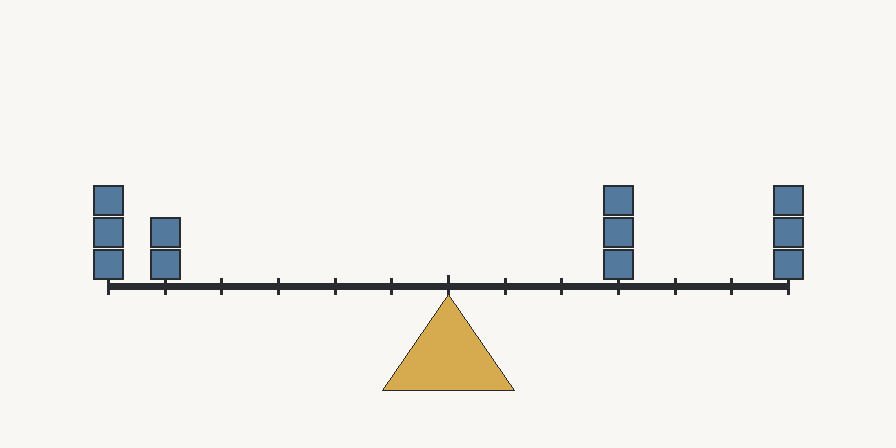

Solve this balance-scale question using only the supplied scene.

Each square is one unit of weight. Distance is measured in tick intervals from the central pivot. A stack's turning effect is its number of squares multiplied by its distance. Add the turning effects on each side and compare the two side totals.

Question: What happens to the balance scale?

Options:
A. The left side moves downward
B. The beam remains level
C. The right side moves downward

Do not explain your reasoning. Reply with exactly one option letter and nothing else. Valid replies are: A, B, C.

Outcome: balanced | weight cue: right
Question: q_single_lu1_ld6_ru3_rd2_outcome_p4 | gold: A


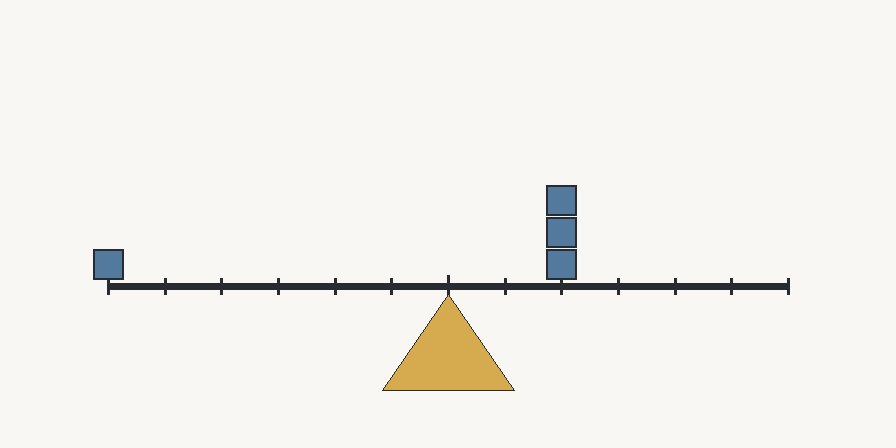

Solve this balance-scale question using only the supplied scene.

Each square is one unit of weight. Distance is measured in tick intervals from the central pivot. A stack's turning effect is its number of squares multiplied by its distance. Add the turning effects on each side and compare the two side totals.

Question: What happens to the balance scale?

Options:
A. The beam remains level
B. The left side moves downward
C. The right side moves downward

Do not explain your reasoning. Reply with exactly one option letter and nothing else. Valid replies are: A, B, C.

Outcome: right | weight cue: left
Question: q_single_lu4_ld2_ru3_rd6_outcome_p2 | gold: A


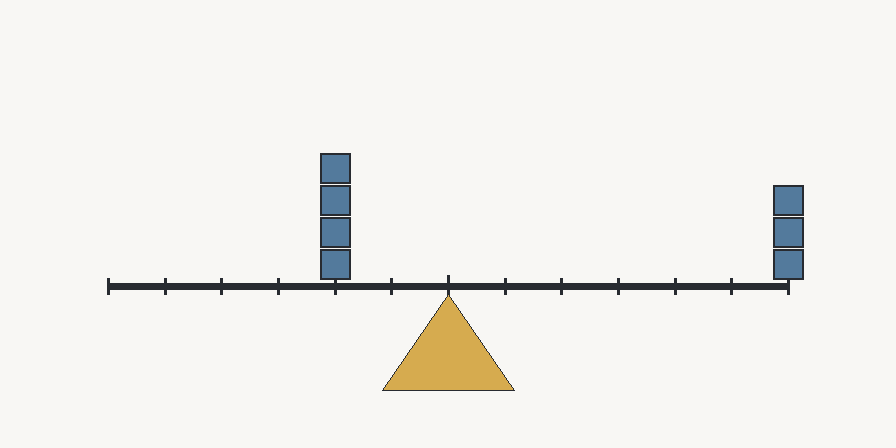

Solve this balance-scale question using only the supplied scene.

Each square is one unit of weight. Distance is measured in tick intervals from the central pivot. A stack's turning effect is its number of squares multiplied by its distance. Add the turning effects on each side and compare the two side totals.

Question: What happens to the balance scale?

Options:
A. The right side moves downward
B. The left side moves downward
C. The beam remains level

Do not explain your reasoning. Reply with exactly one option letter and nothing else. Valid replies are: A, B, C.


,training_instance_id,scene_id,source_question_id,source_split,gold_label,outcome,weight_cue,shortcut_relation,problem_type,cell_repeat_index
0,multi_5b08aed0ea6d53a9__occ000__q_multi_5b08ae...,multi_5b08aed0ea6d53a9,q_multi_5b08aed0ea6d53a9_outcome_p1,probe_train,A,left,right,weight_conflict,multi_stack,0
1,single_lu1_ld6_ru3_rd2__occ002__q_single_lu1_l...,single_lu1_ld6_ru3_rd2,q_single_lu1_ld6_ru3_rd2_outcome_p4,probe_train,A,balanced,right,weight_conflict,conflict_balance,2
2,single_lu4_ld2_ru3_rd6__occ000__q_single_lu4_l...,single_lu4_ld2_ru3_rd6,q_single_lu4_ld2_ru3_rd6_outcome_p2,probe_train,A,right,left,weight_conflict,conflict_distance,0


In [10]:
%%cell_progress 9/16 Preview the realized supervision without training
cell_stage('Displaying one deterministic example from each physical outcome')
from PIL import Image

preview_rows = []
for outcome in SIDES:
    candidate_indices = [
        index for index, row in enumerate(train_manifest)
        if row['outcome'] == outcome and row['gold_label'] == 'A'
    ]
    assert candidate_indices
    selected_index = min(
        candidate_indices,
        key=lambda index: stable_key(train_manifest[index]['training_instance_id']),
    )
    example = train_examples[selected_index]
    row = train_manifest[selected_index]
    print('\n' + '=' * 80)
    print('Outcome:', outcome, '| weight cue:', row['weight_cue'])
    print('Question:', example.question_id, '| gold:', example.gold_label)
    display(Image.open(example.image_path).convert('RGB'))
    print(example.prompt)
    preview_rows.append(row)

display(pd.DataFrame(preview_rows))


## 2. Pre-training behavioral measurement

Before inserting any adapter, the official BF16 checkpoint is evaluated on all six answer mappings for every frozen `probe_test` scene.


In [11]:
%%cell_progress 10/16 Load the pinned non-quantized Qwen3.5-27B checkpoint
cell_stage('Loading the official BF16 checkpoint')
import gc

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='auto',
)
adapter.model.config.use_cache = False
if hasattr(adapter.model, 'generation_config'):
    adapter.model.generation_config.use_cache = False
assert adapter.metadata['resolved_revision'] == MODEL_REVISION, adapter.metadata

quantization_config = getattr(adapter.model.config, 'quantization_config', None)
assert quantization_config is None, (
    'This experiment requires the original non-quantized BF16 checkpoint.',
    quantization_config,
)
device_map = getattr(adapter.model, 'hf_device_map', {}) or {}
offloaded = {
    name: placement for name, placement in device_map.items()
    if str(placement).lower() in {'cpu', 'disk'}
}
assert not offloaded, ('CPU/disk offload is not allowed in this protocol.', offloaded)

def resolve_module_path(root, module_path):
    value = root
    for component in module_path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for module_path in candidates:
        try:
            layers = resolve_module_path(model, module_path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return module_path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
parameter_storage_gib = sum(
    parameter.numel() * parameter.element_size()
    for parameter in adapter.model.parameters()
) / 2**30
assert parameter_storage_gib > 45, (
    'Loaded storage is unexpectedly small for BF16 27B.', parameter_storage_gib
)
print('Layer path:', LAYER_PATH)
print('Decoder layers:', len(DECODER_LAYERS))
print('Parameter storage (GiB):', round(parameter_storage_gib, 2))
print('CUDA allocated (GiB):', round(torch.cuda.memory_allocated() / 2**30, 2))
display(adapter.metadata)


Load the pinned non-quantized Qwen3.5-27B checkpoint:  56%|#####6    | 9/16 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Layer path: model.language_model.layers
Decoder layers: 64
Parameter storage (GiB): 50.96
CUDA allocated (GiB): 50.96


{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

In [12]:
%%cell_progress 11/16 Score the frozen test set before fine-tuning
cell_stage('Defining resumable six-mapping semantic evaluation')

def shard_path(shard_dir, example_id):
    digest = hashlib.sha256(example_id.encode('utf-8')).hexdigest()[:24]
    return Path(shard_dir) / f'{digest}.json'

def evaluate_examples(examples, shard_dir, run_name):
    shard_dir = Path(shard_dir)
    shard_dir.mkdir(parents=True, exist_ok=True)
    pending = [
        example for example in examples
        if not shard_path(shard_dir, example.example_id).is_file()
    ]
    adapter.model.eval()
    for start in tqdm(
        range(0, len(pending), EVAL_BATCH_SIZE),
        desc=f'{run_name} evaluation', unit='batch',
    ):
        batch = pending[start:start + EVAL_BATCH_SIZE]
        results = adapter.score_batch(batch)
        for example, result in zip(batch, results):
            semantic_scores = {
                str(example.label_to_semantic[label]): float(score)
                for label, score in result.logprob_by_label.items()
            }
            scene = scene_by_id[example.scene_id]
            payload = {
                'run_name': run_name,
                'example_id': example.example_id,
                'question_id': example.question_id,
                'scene_id': example.scene_id,
                'variant': example.variant,
                'problem_type': example.problem_type,
                'outcome': example.outcome,
                'net_torque': int(example.net_torque),
                'weight_cue': weight_cue(scene),
                'shortcut_relation': shortcut_relation(scene),
                'balanced_shortcut_test': example.scene_id in test_balanced_ids,
                'logprob_by_semantic': semantic_scores,
                'scoring_mode': result.scoring_mode,
            }
            write_json_atomic(shard_path(shard_dir, example.example_id), payload)

    rows = [
        json.loads(path.read_text(encoding='utf-8'))
        for path in sorted(shard_dir.glob('*.json'))
    ]
    expected_ids = {example.example_id for example in examples}
    rows = [row for row in rows if row['example_id'] in expected_ids]
    assert {row['example_id'] for row in rows} == expected_ids
    return rows

def aggregate_six_mapping_rows(rows):
    question_frame = pd.DataFrame(rows)
    scene_outputs = []
    for scene_id, current in question_frame.groupby('scene_id'):
        assert len(current) == 6, (scene_id, len(current))
        mean_scores = {
            semantic: float(np.mean([
                scores[semantic]
                for scores in current['logprob_by_semantic']
            ]))
            for semantic in SIDES
        }
        prediction = max(SIDES, key=lambda semantic: mean_scores[semantic])
        first = current.iloc[0]
        cue = first['weight_cue']
        scene_outputs.append({
            'scene_id': scene_id,
            'problem_type': first['problem_type'],
            'outcome': first['outcome'],
            'net_torque': int(first['net_torque']),
            'weight_cue': cue,
            'shortcut_relation': first['shortcut_relation'],
            'balanced_shortcut_test': bool(first['balanced_shortcut_test']),
            'prediction': prediction,
            'correct': prediction == first['outcome'],
            'follows_weight': prediction == cue,
            **{f'score_{semantic}': mean_scores[semantic] for semantic in SIDES},
        })
    return pd.DataFrame(scene_outputs).sort_values('scene_id').reset_index(drop=True)

def metric_row(frame, subset_name):
    conflict = frame['shortcut_relation'] == 'weight_conflict'
    informative = frame['weight_cue'] != 'balanced'
    return {
        'subset': subset_name,
        'scenes': int(len(frame)),
        'accuracy': float(frame['correct'].mean()),
        'weight_follow_rate': float(frame.loc[informative, 'follows_weight'].mean()),
        'conflict_accuracy': float(frame.loc[conflict, 'correct'].mean()),
        'conflict_weight_follow_rate': float(
            frame.loc[conflict, 'follows_weight'].mean()
        ),
    }

def summarize_scene_predictions(scene_predictions):
    return pd.DataFrame([
        metric_row(scene_predictions, 'all_probe_test'),
        metric_row(
            scene_predictions[scene_predictions['balanced_shortcut_test']],
            'balanced_shortcut_test',
        ),
        metric_row(
            scene_predictions[scene_predictions['problem_type'] == 'multi_stack'],
            'multi_stack',
        ),
    ])

if RUN_BASELINE_EVALUATION:
    baseline_rows = evaluate_examples(
        test_examples, BASELINE_SHARD_DIR, 'bf16_base'
    )
    baseline_scene_frame = aggregate_six_mapping_rows(baseline_rows)
    baseline_summary = summarize_scene_predictions(baseline_scene_frame)
    baseline_scene_frame.to_csv(
        ANALYSIS_DIR / 'baseline_scene_predictions.csv', index=False
    )
    baseline_summary.to_csv(
        ANALYSIS_DIR / 'baseline_shortcut_summary.csv', index=False
    )
    display(baseline_summary.round(4))
else:
    print('Baseline evaluation disabled. Enable it for a publishable comparison.')


Score the frozen test set before fine-tuning:  62%|######2   | 10/16 [00:00<?, ?cell/s]

bf16_base evaluation: 0batch [00:00, ?batch/s]

,subset,scenes,accuracy,weight_follow_rate,conflict_accuracy,conflict_weight_follow_rate
0,all_probe_test,1007,0.5223,0.5548,0.4327,0.4795
1,balanced_shortcut_test,99,0.3838,0.5303,0.2500,0.5000
2,multi_stack,683,0.5344,0.5538,0.4530,0.4701


## 3. Decoder-only BF16 LoRA

LoRA is attached to linear modules discovered inside all 64 decoder layers.


In [13]:
%%cell_progress 12/16 Attach decoder-only LoRA adapters
cell_stage('Discovering decoder linear-module suffixes')
linear_leaf_names = sorted({
    module_name.rsplit('.', 1)[-1]
    for layer in DECODER_LAYERS
    for module_name, module in layer.named_modules()
    if module_name and isinstance(module, torch.nn.Linear)
})
assert linear_leaf_names, 'No decoder linear modules were found.'
print('Decoder linear suffixes:', linear_leaf_names)

cell_stage('Injecting LoRA and freezing non-decoder adapters')
lora_config = LoraConfig(
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias='none',
    target_modules=linear_leaf_names,
    task_type='CAUSAL_LM',
)
adapter.model = get_peft_model(adapter.model, lora_config)

# Suffix matching can also inject adapters into similarly named vision modules.
# Keep only adapters under the previously discovered decoder-layer path trainable.
for parameter_name, parameter in adapter.model.named_parameters():
    if 'lora_' in parameter_name and LAYER_PATH not in parameter_name:
        parameter.requires_grad_(False)

trainable = [
    (name, parameter) for name, parameter in adapter.model.named_parameters()
    if parameter.requires_grad
]
assert trainable, 'No trainable decoder LoRA parameters remain.'
assert all('lora_' in name and LAYER_PATH in name for name, _ in trainable)
trainable_count = sum(parameter.numel() for _, parameter in trainable)
total_count = sum(parameter.numel() for parameter in adapter.model.parameters())
trainable_ratio = trainable_count / total_count
assert trainable_ratio < 0.02, trainable_ratio

adapter.model.config.use_cache = False
adapter.model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={'use_reentrant': False}
)
if hasattr(adapter.model, 'enable_input_require_grads'):
    adapter.model.enable_input_require_grads()
adapter.model.print_trainable_parameters()
print('Trainable decoder LoRA parameters:', f'{trainable_count:,}')
print('Trainable ratio:', f'{100 * trainable_ratio:.4f}%')
print('CUDA allocated after LoRA (GiB):', round(
    torch.cuda.memory_allocated() / 2**30, 2
))


Attach decoder-only LoRA adapters:  69%|######8   | 11/16 [00:00<?, ?cell/s]

Decoder linear suffixes: ['down_proj', 'gate_proj', 'in_proj_a', 'in_proj_b', 'in_proj_qkv', 'in_proj_z', 'k_proj', 'o_proj', 'out_proj', 'q_proj', 'up_proj', 'v_proj']
trainable params: 58,363,904 || all params: 27,415,092,464 || trainable%: 0.2129
Trainable decoder LoRA parameters: 58,363,904
Trainable ratio: 0.2129%
CUDA allocated after LoRA (GiB): 51.17


In [14]:
%%cell_progress 13/16 Build the multimodal completion-only collator and run a loss smoke test
cell_stage('Defining indexed datasets and exact-label supervision')

class IndexedExampleDataset(Dataset):
    def __init__(self, examples):
        self.examples = list(examples)

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return {'example_index': int(index)}

class SingleExampleCompletionCollator:
    def __init__(self, examples, behavior_adapter):
        self.examples = list(examples)
        self.adapter = behavior_adapter
        eos = self.adapter.processor.tokenizer.eos_token_id
        if isinstance(eos, (tuple, list)):
            eos = eos[0]
        assert eos is not None
        self.eos_token_id = int(eos)

    def __call__(self, features):
        assert len(features) == 1, (
            'This correctness-first multimodal collator requires batch size 1.'
        )
        example = self.examples[int(features[0]['example_index'])]
        prompt_inputs = self.adapter._template(
            [example.messages()], add_generation_prompt=True
        )
        prompt_width = int(prompt_inputs['input_ids'].shape[1])
        completion = (
            *self.adapter._literal_completion_tokens(example.gold_label),
            self.eos_token_id,
        )
        full_inputs = self.adapter._append_text_prefix(
            dict(prompt_inputs), tuple(completion)
        )
        for aligned_key in (
            'attention_mask', 'token_type_ids', 'mm_token_type_ids'
        ):
            aligned = full_inputs.get(aligned_key)
            if aligned is not None and aligned.ndim == 2:
                assert aligned.shape == full_inputs['input_ids'].shape, (
                    aligned_key, aligned.shape, full_inputs['input_ids'].shape
                )
        labels = full_inputs['input_ids'].clone()
        labels[:, :prompt_width] = -100
        full_inputs['labels'] = labels
        assert int((labels != -100).sum()) == len(completion)
        return full_inputs

train_dataset = IndexedExampleDataset(train_examples)
dev_dataset = IndexedExampleDataset(dev_examples)
train_collator = SingleExampleCompletionCollator(train_examples, adapter)
dev_collator = SingleExampleCompletionCollator(dev_examples, adapter)

# Trainer accepts one collator. Train/dev examples are kept in a single indexed
# table so both datasets resolve indices through the same object.
combined_examples = train_examples + dev_examples
train_dataset = IndexedExampleDataset(train_examples)
dev_offset = len(train_examples)

class OffsetDataset(Dataset):
    def __init__(self, length, offset=0):
        self.length = int(length)
        self.offset = int(offset)

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        return {'example_index': self.offset + int(index)}

train_dataset = OffsetDataset(len(train_examples), 0)
dev_dataset = OffsetDataset(len(dev_examples), dev_offset)
training_collator = SingleExampleCompletionCollator(combined_examples, adapter)

cell_stage('Running one no-update BF16 loss check')
smoke_batch = training_collator([train_dataset[0]])
smoke_batch = adapter._to_device(smoke_batch)
adapter.model.eval()
with torch.no_grad():
    smoke_output = adapter.model(**smoke_batch, use_cache=False)
assert torch.isfinite(smoke_output.loss), smoke_output.loss
print('Smoke loss:', float(smoke_output.loss.item()))
print('Input width:', smoke_batch['input_ids'].shape[1])
print('Supervised tokens:', int((smoke_batch['labels'] != -100).sum()))
del smoke_output, smoke_batch
gc.collect()
torch.cuda.empty_cache()


Build the multimodal completion-only collator and run a loss smoke test:  75%|#######5  | 12/16 [00:00<?, ?cel…

Smoke loss: 0.469624400138855
Input width: 532
Supervised tokens: 2


In [15]:
%%cell_progress 14/16 Fine-tune and save the resumable adapter
cell_stage('Configuring single-GPU BF16 LoRA training')
from transformers.trainer_utils import get_last_checkpoint

training_arguments = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=NUM_TRAIN_EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type='cosine',
    bf16=True,
    tf32=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False},
    optim='adamw_torch_fused',
    max_grad_norm=1.0,
    logging_steps=LOGGING_STEPS,
    eval_strategy='steps',
    eval_steps=EVAL_STEPS,
    save_strategy='steps',
    save_steps=SAVE_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    remove_unused_columns=False,
    dataloader_num_workers=0,
    report_to='none',
    seed=SEED,
    data_seed=SEED,
)

trainer = Trainer(
    model=adapter.model,
    args=training_arguments,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    data_collator=training_collator,
)
last_checkpoint = get_last_checkpoint(str(CHECKPOINT_DIR))
if last_checkpoint:
    print('Resuming from:', last_checkpoint)
else:
    print('Starting a fresh LoRA run.')

cell_stage('Running outcome-only shortcut-balanced SFT')
train_result = trainer.train(resume_from_checkpoint=last_checkpoint)
trainer.save_model(str(ADAPTER_DIR))
adapter.processor.save_pretrained(str(ADAPTER_DIR))
write_json_atomic(OUTPUT_ROOT / 'training_metrics.json', {
    key: float(value) if isinstance(value, (np.floating, float)) else value
    for key, value in train_result.metrics.items()
})
print('Final adapter:', ADAPTER_DIR)
display(pd.DataFrame([train_result.metrics]))


Fine-tune and save the resumable adapter:  81%|########1 | 13/16 [00:00<?, ?cell/s]

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Starting a fresh LoRA run.


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss,Validation Loss
25,0.257885,0.254939
50,0.125397,0.163670
68,0.233776,0.197872


Final adapter: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1/adapter_final


,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss,epoch
0,2043.518,0.529,0.033,9.011758e+16,0.274028,1.0


## 4. Frozen post-LoRA test and causal handoff

The identical six-mapping `probe_test` set is evaluated after training.


Evaluate whether the weight shortcut changed:  88%|########7 | 14/16 [00:00<?, ?cell/s]

bf16_lora evaluation:   0%|          | 0/3021 [00:00<?, ?batch/s]

,subset,scenes_base,accuracy_base,weight_follow_rate_base,conflict_accuracy_base,conflict_weight_follow_rate_base,scenes_lora,accuracy_lora,weight_follow_rate_lora,conflict_accuracy_lora,conflict_weight_follow_rate_lora
0,all_probe_test,1007,0.5223,0.5548,0.4327,0.4795,1007,0.8868,0.7690,0.7661,0.1111
1,balanced_shortcut_test,99,0.3838,0.5303,0.2500,0.5000,99,0.7374,0.4242,0.6818,0.1364
2,multi_stack,683,0.5344,0.5538,0.4530,0.4701,683,0.8785,0.7813,0.7350,0.1453


,mean,ci_low,ci_high
balanced_test_accuracy_change,0.3535,0.2525,0.4545
conflict_accuracy_change,0.4318,0.2500,0.5909
conflict_weight_follow_change,-0.3636,-0.5455,-0.1818


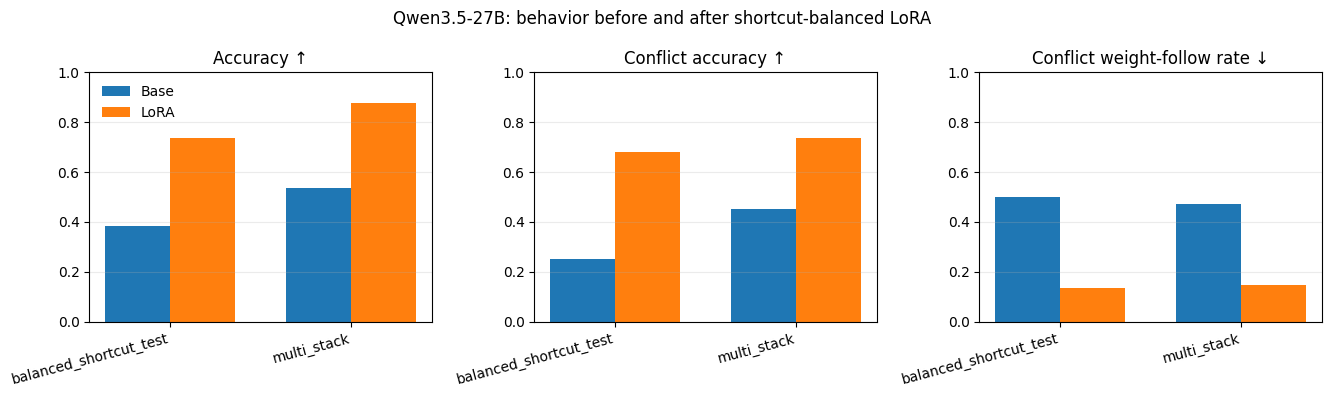

Figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1/analysis/figures/pre_post_weight_shortcut.png


In [16]:
%%cell_progress 15/16 Evaluate whether the weight shortcut changed
cell_stage('Scoring the identical frozen test set with the LoRA adapter')
adapter.model.eval()
adapted_rows = evaluate_examples(
    test_examples, ADAPTED_SHARD_DIR, 'bf16_lora'
)
adapted_scene_frame = aggregate_six_mapping_rows(adapted_rows)
adapted_summary = summarize_scene_predictions(adapted_scene_frame)
adapted_scene_frame.to_csv(
    ANALYSIS_DIR / 'adapted_scene_predictions.csv', index=False
)
adapted_summary.to_csv(
    ANALYSIS_DIR / 'adapted_shortcut_summary.csv', index=False
)

assert RUN_BASELINE_EVALUATION, (
    'Enable baseline evaluation for the pre/post scientific comparison.'
)
comparison = baseline_scene_frame.merge(
    adapted_scene_frame,
    on='scene_id', suffixes=('_base', '_lora'), validate='one_to_one',
)
comparison['delta_correct'] = (
    comparison['correct_lora'].astype(float)
    - comparison['correct_base'].astype(float)
)
comparison['delta_follows_weight'] = (
    comparison['follows_weight_lora'].astype(float)
    - comparison['follows_weight_base'].astype(float)
)
comparison.to_csv(ANALYSIS_DIR / 'paired_pre_post_scenes.csv', index=False)

def paired_bootstrap_mean(values, key):
    array = np.asarray(values, dtype=float)
    generator = np.random.default_rng(
        int(stable_key(f'bootstrap:{key}')[:16], 16) % (2**63 - 1)
    )
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for start in range(0, BOOTSTRAP_REPLICATES, 1000):
        count = min(1000, BOOTSTRAP_REPLICATES - start)
        indices = generator.integers(0, len(array), size=(count, len(array)))
        draws[start:start + count] = array[indices].mean(axis=1)
    return {
        'mean': float(array.mean()),
        'ci_low': float(np.quantile(draws, 0.025)),
        'ci_high': float(np.quantile(draws, 0.975)),
    }

primary = comparison[comparison['balanced_shortcut_test_base']].copy()
primary_conflict = primary[
    primary['shortcut_relation_base'] == 'weight_conflict'
].copy()
paired_effects = {
    'balanced_test_accuracy_change': paired_bootstrap_mean(
        primary['delta_correct'], 'balanced-accuracy'
    ),
    'conflict_accuracy_change': paired_bootstrap_mean(
        primary_conflict['delta_correct'], 'conflict-accuracy'
    ),
    'conflict_weight_follow_change': paired_bootstrap_mean(
        primary_conflict['delta_follows_weight'], 'conflict-weight-follow'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'paired_bootstrap_effects.json', paired_effects)

summary_comparison = baseline_summary.merge(
    adapted_summary,
    on='subset', suffixes=('_base', '_lora'), validate='one_to_one',
)
summary_comparison.to_csv(
    ANALYSIS_DIR / 'pre_post_shortcut_summary.csv', index=False
)
display(summary_comparison.round(4))
display(pd.DataFrame(paired_effects).T.round(4))

cell_stage('Plotting behavior and shortcut movement')
plot_frame = summary_comparison[
    summary_comparison['subset'].isin(('balanced_shortcut_test', 'multi_stack'))
].copy()
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
metrics = (
    ('accuracy', 'Accuracy', True),
    ('conflict_accuracy', 'Conflict accuracy', True),
    ('conflict_weight_follow_rate', 'Conflict weight-follow rate', False),
)
x = np.arange(len(plot_frame))
width = 0.36
for axis, (metric, title, higher_is_better) in zip(axes, metrics):
    axis.bar(x - width / 2, plot_frame[f'{metric}_base'], width, label='Base')
    axis.bar(x + width / 2, plot_frame[f'{metric}_lora'], width, label='LoRA')
    axis.set_xticks(x, plot_frame['subset'], rotation=15, ha='right')
    axis.set_ylim(0, 1)
    axis.set_title(title + (' ↑' if higher_is_better else ' ↓'))
    axis.grid(axis='y', alpha=0.25)
axes[0].legend(frameon=False)
fig.suptitle('Qwen3.5-27B: behavior before and after shortcut-balanced LoRA')
fig.tight_layout()
figure_path = FIGURE_DIR / 'pre_post_weight_shortcut.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Figure:', figure_path)


In [17]:
%%cell_progress 16/16 Finalize reproducibility records and next-stage handoff
cell_stage('Hashing adapter, manifests, and scientific outputs')

def hash_tree(directory):
    directory = Path(directory)
    return {
        str(path.relative_to(directory)): sha256_file(path)
        for path in sorted(directory.rglob('*'))
        if path.is_file()
    }

required_outputs = (
    PROTOCOL_LOCK_PATH,
    MANIFEST_DIR / 'train_manifest.jsonl',
    MANIFEST_DIR / 'dev_manifest.jsonl',
    MANIFEST_DIR / 'test_manifest.jsonl',
    ADAPTER_DIR / 'adapter_config.json',
    ANALYSIS_DIR / 'baseline_scene_predictions.csv',
    ANALYSIS_DIR / 'adapted_scene_predictions.csv',
    ANALYSIS_DIR / 'pre_post_shortcut_summary.csv',
    ANALYSIS_DIR / 'paired_bootstrap_effects.json',
)
for required in required_outputs:
    assert Path(required).is_file(), required

adapter_manifest = {
    'schema_version': 'visualtorque-lora-adapter-1.0',
    'base_model_id': MODEL_ID,
    'base_model_revision': MODEL_REVISION,
    'base_precision': MODEL_DTYPE,
    'adapter_path': str(ADAPTER_DIR),
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'train_manifest_sha256': sha256_file(
        MANIFEST_DIR / 'train_manifest.jsonl'
    ),
    'dev_manifest_sha256': sha256_file(MANIFEST_DIR / 'dev_manifest.jsonl'),
    'test_manifest_sha256': sha256_file(MANIFEST_DIR / 'test_manifest.jsonl'),
    'adapter_files': hash_tree(ADAPTER_DIR),
    'trainable_parameters': int(trainable_count),
    'trainable_ratio': float(trainable_ratio),
    'dataset_fingerprint': dataset_fingerprint,
    'recommended_mechanism_comparison': [
        'Run the existing frozen Qwen-27B sites first with adapter disabled and enabled.',
        'Then perform a separate post-LoRA discovery scan on probe_train/probe_dev.',
        'Freeze any relocated layers before evaluating probe_test/intervention_test.',
        'Do not call behavioral improvement a repaired torque mechanism without causal evidence.',
    ],
}
write_json_atomic(OUTPUT_ROOT / 'ADAPTER_MANIFEST.json', adapter_manifest)

run_complete = {
    'status': 'complete',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(
        OUTPUT_ROOT / 'ADAPTER_MANIFEST.json'
    ),
    'primary_behavioral_outputs': {
        'summary': str(ANALYSIS_DIR / 'pre_post_shortcut_summary.csv'),
        'paired_effects': str(ANALYSIS_DIR / 'paired_bootstrap_effects.json'),
        'figure': str(FIGURE_DIR / 'pre_post_weight_shortcut.png'),
    },
    'claim_limit': (
        'The completed run can establish a change in held-out behavior and '
        'weight-following. Mechanism repair requires the frozen causal follow-up.'
    ),
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', run_complete)

print('Run complete:', OUTPUT_ROOT / 'RUN_COMPLETE.json')
print('\nNext scientific step:')
for item in adapter_manifest['recommended_mechanism_comparison']:
    print('-', item)


Finalize reproducibility records and next-stage handoff:  94%|#########3| 15/16 [00:00<?, ?cell/s]

Run complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_bf16_lora_weight_shortcut_v1/RUN_COMPLETE.json

Next scientific step:
- Run the existing frozen Qwen-27B sites first with adapter disabled and enabled.
- Then perform a separate post-LoRA discovery scan on probe_train/probe_dev.
- Freeze any relocated layers before evaluating probe_test/intervention_test.
- Do not call behavioral improvement a repaired torque mechanism without causal evidence.
